# Graph Models: Implementation and Verification

Implements LightGCN, NGCF and GraphSAGE, and verifies that the implementations are correct before training on the Amazon data. Since there are no published results for Amazon Electronics, correctness has to be established independently.

Three complementary verification steps are used:

- **0-layer identity.** LightGCN with zero propagation layers is exactly matrix factorisation. With the same seed it should produce identical embeddings and training results to the BPR-MF implementation from Notebook 08. This verifies the embedding tables, BPR loss, sampler, training loop and evaluator without involving graph propagation.

- **Propagation recomputed by hand.** One node's layer-1 embedding is calculated directly from its neighbours and compared with the model output, confirming that propagation follows the stated formula.

- **Reproduction against published results.** LightGCN and NGCF are trained on the official Gowalla files released with the original papers, using the published protocols and hyperparameters. This verifies the implementations independently before evaluating them on Amazon.

GraphSAGE has no comparable published benchmark on these datasets, so it is verified structurally but not reproduced. It is therefore treated as an implementation rather than a reproduction.

All three models share the same embedding construction and differ only in their propagation mechanism. The metadata feature hook is implemented here but remains disabled until Notebook 11.

In [1]:
%load_ext autoreload
%autoreload 2

import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
import torch

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src import evaluation as ev
from src import features as ft
from src import graph as gr
from src import models as md
from src import training as tr

# Paths 
SUBSETS_DIR = PROJECT_ROOT / "data" / "processed" / "subsets_earliest"
FEATURES_DIR = PROJECT_ROOT / "data" / "processed" / "features_earliest"
BENCHMARK_DIR = PROJECT_ROOT / "data" / "benchmark" / "lightgcn"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"

for directory in (BENCHMARK_DIR, RESULTS_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

# Config
SUBSET = "small"
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Defaults used for verification only. Tuning happens in Notebook 10, so nothing
# selected here should be treated as a chosen configuration.
VERIFY_DIM = 32
VERIFY_LAYERS = 3

# LightGCN paper settings, used for the reproduction. Their lambda of 1e-4 becomes
# 5e-5 here (GOWALLA_L2), because their loss carries a factor of 1/2 in the norm that
# this training loop does not.
LIGHTGCN_PAPER = {
    "dim": 64,
    "layers": 3,
    "learning_rate": 1e-3,
    "batch_size": 2048,
}

torch.manual_seed(SEED)
np.random.seed(SEED)

print(f"device: {DEVICE}")
print(f"verification settings: dim {VERIFY_DIM}, layers {VERIFY_LAYERS}")
print(f"reproduction settings: {LIGHTGCN_PAPER}")

device: cuda
verification settings: dim 32, layers 3
reproduction settings: {'dim': 64, 'layers': 3, 'learning_rate': 0.001, 'batch_size': 2048}


## 2. Load the graph and splits

Only the `small` dataset under the `last_out` protocol is needed for verification.

Item features are loaded only to verify that the feature projection has the correct shape. The models themselves are constructed without metadata.

In [4]:
graph = gr.load_graph(SUBSETS_DIR, SUBSET, "last_out")
n_users, n_items, n_nodes = graph["n_users"], graph["n_items"], graph["n_nodes"]
edge_index = graph["edge_index"].to(DEVICE)

adjacency = gr.normalised_adjacency(edge_index, n_nodes, device=DEVICE)
mean_adj = gr.mean_adjacency(edge_index, n_nodes, device=DEVICE)

splits_dir = SUBSETS_DIR / SUBSET / "splits" / "last_out"
splits = {
    name: pq.read_table(splits_dir / f"{name}.parquet",
                        columns=["user_idx", "item_idx"]).to_pandas()
    for name in ["train", "validation", "test"]
}
eval_users = pq.read_table(
    splits_dir / "eval_users.parquet").to_pandas()["user_idx"].to_numpy()

# small evaluator: verification only, so precision matters less than speed
verify_evaluator = ev.Evaluator.from_frames(
    ground_truth=splits["validation"],
    mask_frames=[splits["train"]],
    eval_users=eval_users[:10_000],
    n_users=n_users, n_items=n_items,
    k_values=[10, 20], device=DEVICE, batch_users=1024,
)

item_features = ft.load_item_features(FEATURES_DIR, SUBSETS_DIR, SUBSET, encoder="blair")

print(f"{n_users:,} users, {n_items:,} items, {n_nodes:,} nodes")
print(f"{edge_index.shape[1]:,} directed edges")
print(f"item features: {item_features.shape}")

c:\Projects\gnn-recommender-dissertation\src\graph.py:78: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:767.)
  adj = torch.sparse_coo_tensor(


258,597 users, 105,298 items, 363,895 nodes
3,659,164 directed edges
item features: (105298, 807)


## 3. Verification

Four checks verify different parts of the implementation.

- **0-layer identity.** LightGCN with zero propagation layers reduces to matrix factorisation. With the same seed, both models should produce identical embeddings and training results. This verifies the embedding tables, BPR loss, sampler, training loop and evaluator.

- **Propagation by hand.** One node's layer-1 embedding is computed manually from its neighbours and compared with the model output, verifying the propagation step.

- **Shapes.** NGCF concatenates embeddings from all layers, while GraphSAGE returns only the final layer. Checking the output shapes confirms each model follows its intended architecture.

- **Feature hook.** The feature projection is zero-initialised, so enabling metadata should initially produce identical outputs to the feature-free model. This verifies that metadata can be enabled later without changing the collaborative model.

In [5]:
mf = md.MatrixFactorization(n_users, n_items, VERIFY_DIM, SEED).to(DEVICE)
lgcn0 = md.LightGCN(n_users, n_items, dim=VERIFY_DIM, seed=SEED,
                    adjacency=adjacency, n_layers=0).to(DEVICE)

mf_users, mf_items = mf()
lg_users, lg_items = lgcn0()

print(f"user embeddings identical: {torch.equal(mf_users, lg_users)}")
print(f"item embeddings identical: {torch.equal(mf_items, lg_items)}")
print(f"max absolute difference : {(mf_items - lg_items).abs().max():.2e}")

assert torch.equal(mf_users, lg_users)
assert torch.equal(mf_items, lg_items)

user embeddings identical: True
item embeddings identical: True
max absolute difference : 0.00e+00


In [6]:
mf_trained = tr.train_bpr(
    md.MatrixFactorization(n_users, n_items, VERIFY_DIM, SEED),
    splits["train"], n_items, evaluator=None, epochs=5,
    batch_size=8192, learning_rate=1e-3, l2_reg=0.05,
    device=DEVICE, seed=SEED, verbose=False,
)["model"]

lgcn0_trained = tr.train_bpr(
    md.LightGCN(n_users, n_items, dim=VERIFY_DIM, seed=SEED,
                adjacency=adjacency, n_layers=0),
    splits["train"], n_items, evaluator=None, epochs=5,
    batch_size=8192, learning_rate=1e-3, l2_reg=0.05,
    device=DEVICE, seed=SEED, verbose=False,
)["model"]

a_users, a_items = mf_trained()
b_users, b_items = lgcn0_trained()

print(f"after 5 epochs, max user difference: {(a_users - b_users).abs().max():.2e}")
print(f"after 5 epochs, max item difference: {(a_items - b_items).abs().max():.2e}")

assert torch.allclose(a_users, b_users, atol=1e-6)
assert torch.allclose(a_items, b_items, atol=1e-6)
print("\n0-layer LightGCN is identical to BPR-MF, before and after training")

c:\Projects\gnn-recommender-dissertation\src\training.py:65: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  users = torch.as_tensor(train["user_idx"].to_numpy(), dtype=torch.long, device=device)
c:\Projects\gnn-recommender-dissertation\src\training.py:128: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  epoch_loss += float(loss) * len(batch)


after 5 epochs, max user difference: 8.94e-08
after 5 epochs, max item difference: 5.96e-08

0-layer LightGCN is identical to BPR-MF, before and after training


In [7]:
# take a node with a manageable number of neighbours and recompute its layer-1
# embedding directly from the definition
degrees = gr.node_degrees(edge_index, n_nodes)
candidates = torch.nonzero((degrees > 5) & (degrees < 20)).flatten()
node = int(candidates[0])

neighbours = edge_index[1][edge_index[0] == node]
base_users, base_items = lgcn0.base_embeddings()
base = torch.cat([base_users, base_items], dim=0)

# layer 1 for node i is the sum over neighbours j of e_j / sqrt(deg_i * deg_j)
manual = torch.zeros(VERIFY_DIM, device=DEVICE)
for j in neighbours:
    manual += base[j] / torch.sqrt(degrees[node] * degrees[j])

from_model = torch.sparse.mm(adjacency, base)[node]

print(f"node {node}, degree {int(degrees[node])}, {len(neighbours)} neighbours")
print(f"max difference between manual and model: "
      f"{(manual - from_model).abs().max():.2e}")

assert torch.allclose(manual, from_model, atol=1e-5)
print("propagation matches the definition")

node 3, degree 6, 6 neighbours
max difference between manual and model: 7.45e-09
propagation matches the definition


In [8]:
lgcn = md.LightGCN(n_users, n_items, dim=VERIFY_DIM, seed=SEED,
                   adjacency=adjacency, n_layers=VERIFY_LAYERS).to(DEVICE)
ngcf = md.NGCF(n_users, n_items, dim=VERIFY_DIM, seed=SEED,
               adjacency=adjacency, n_layers=VERIFY_LAYERS).to(DEVICE)
sage = md.GraphSAGE(n_users, n_items, dim=VERIFY_DIM, seed=SEED,
                    adjacency=mean_adj, n_layers=2).to(DEVICE)

for name, model in [("LightGCN", lgcn), ("NGCF", ngcf), ("GraphSAGE", sage)]:
    model.eval()
    u, i = model()
    params = sum(p.numel() for p in model.parameters())
    print(f"{name:>10}: users {tuple(u.shape)}, items {tuple(i.shape)}, "
          f"{params:,} parameters")

# LightGCN averages layers so keeps its width; NGCF concatenates them
assert lgcn()[0].shape[1] == VERIFY_DIM
assert ngcf()[0].shape[1] == VERIFY_DIM * (VERIFY_LAYERS + 1)
assert sage()[0].shape[1] == VERIFY_DIM

# propagation must actually change something
assert not torch.allclose(lgcn()[0], lgcn0()[0])
print("\npropagation changes the embeddings, shapes are as expected")

  LightGCN: users (258597, 32), items (105298, 32), 11,644,640 parameters
      NGCF: users (258597, 128), items (105298, 128), 11,650,976 parameters
 GraphSAGE: users (258597, 32), items (105298, 32), 11,648,800 parameters

propagation changes the embeddings, shapes are as expected


In [9]:
# zero-initialised projection means the feature model starts identical to the
# feature-free one, which is what makes the metadata ablation a strict nesting
lgcn_features = md.LightGCN(
    n_users, n_items, dim=VERIFY_DIM, seed=SEED, item_features=item_features,
    adjacency=adjacency, n_layers=VERIFY_LAYERS,
).to(DEVICE)
lgcn_features.eval()

fu, fi = lgcn_features()
pu, pi = lgcn()

print(f"feature projection shape: {tuple(lgcn_features.feature_projection.weight.shape)}")
print(f"max item difference with W=0: {(fi - pi).abs().max():.2e}")

assert torch.allclose(fu, pu, atol=1e-6)
assert torch.allclose(fi, pi, atol=1e-6)
print("with the projection at zero, the feature model equals the feature-free model")

feature projection shape: (32, 807)
max item difference with W=0: 1.49e-08
with the projection at zero, the feature model equals the feature-free model


In [10]:
# the difference above should be sparse-mm noise, not the projection.
# check the pre-propagation embeddings, which involve no sparse ops at all
assert torch.equal(lgcn_features.base_embeddings()[1], lgcn.base_embeddings()[1])

# and confirm the same model gives the same size of variation between two calls
print(f"same model, two calls: {(lgcn()[1] - lgcn()[1]).abs().max():.2e}")

same model, two calls: 1.49e-08


In [11]:
# train the SAME model twice with the SAME seed. any difference is GPU nondeterminism,
# not a difference between models
runs = [
    tr.train_bpr(md.MatrixFactorization(n_users, n_items, VERIFY_DIM, SEED),
                 splits["train"], n_items, evaluator=None, epochs=5,
                 batch_size=8192, learning_rate=1e-3, l2_reg=0.05,
                 device=DEVICE, seed=SEED, verbose=False)["model"]
    for _ in range(2)
]
print(f"same model, same seed, two runs: {(runs[0]()[1] - runs[1]()[1]).abs().max():.2e}")

same model, same seed, two runs: 0.00e+00


In [12]:
pair = [
    tr.train_bpr(md.LightGCN(n_users, n_items, dim=VERIFY_DIM, seed=SEED,
                             adjacency=adjacency, n_layers=0),
                 splits["train"], n_items, evaluator=None, epochs=5,
                 batch_size=8192, learning_rate=1e-3, l2_reg=0.05,
                 device=DEVICE, seed=SEED, verbose=False)["model"]
    for _ in range(2)
]
print(f"LightGCN(0) twice, same seed: {(pair[0]()[1] - pair[1]()[1]).abs().max():.2e}")

LightGCN(0) twice, same seed: 0.00e+00


## 4. LightGCN Reproduction on Gowalla

The checks in Section 3 verify the implementation internally, but they do not show that it matches the original LightGCN. That requires comparing against published results on a benchmark dataset.

Gowalla is the primary dataset used in the LightGCN paper, and the authors released the exact train/test files, so preprocessing and splitting are not sources of disagreement. The reported results for the 3-layer model are Recall@20 = 0.1823 and NDCG@20 = 0.1555 (He et al., 2020, Table 3).

The released dataset has no validation split, and the original paper selects the best epoch on the test set. This section follows the published protocol for reproduction and reports both the final epoch and the best-on-test result. All experiments on the Amazon dataset use a separate validation set instead.

In [13]:
import urllib.request

GOWALLA_DIR = BENCHMARK_DIR / "gowalla"
GOWALLA_DIR.mkdir(parents=True, exist_ok=True)

GOWALLA_RESULTS = RESULTS_DIR / "09_gowalla"
GOWALLA_RESULTS.mkdir(parents=True, exist_ok=True)

BASE_URL = ("https://raw.githubusercontent.com/gusye1234/"
            "LightGCN-PyTorch/master/data/gowalla")

for name in ("train.txt", "test.txt"):
    target = GOWALLA_DIR / name
    if target.exists():
        print(f"{name:<10} already present  {target.stat().st_size / 1e6:>5.1f} MB")
        continue
    urllib.request.urlretrieve(f"{BASE_URL}/{name}", target)
    print(f"{name:<10} downloaded       {target.stat().st_size / 1e6:>5.1f} MB")

train.txt  already present    4.6 MB
test.txt   already present    1.4 MB


In [14]:
def load_gowalla(path):
    """Read LightGCN's released format: one line per user, the user id followed by
    the ids of every item that user interacted with."""
    rows = []
    with open(path) as handle:
        for line in handle:
            parts = line.split()
            if len(parts) < 2:
                continue                      # a few users have no items on a side
            user = int(parts[0])
            rows.extend((user, int(item)) for item in parts[1:])
    return pd.DataFrame(rows, columns=["user_idx", "item_idx"])


gow_train = load_gowalla(GOWALLA_DIR / "train.txt")
gow_test = load_gowalla(GOWALLA_DIR / "test.txt")
gow_all = pd.concat([gow_train, gow_test])

GOW_USERS = int(gow_all["user_idx"].max()) + 1
GOW_ITEMS = int(gow_all["item_idx"].max()) + 1
density = len(gow_all) / (GOW_USERS * GOW_ITEMS)

print(f"users         {GOW_USERS:>10,}   paper 29,858")
print(f"items         {GOW_ITEMS:>10,}   paper 40,981")
print(f"interactions  {len(gow_all):>10,}   paper 1,027,370")
print(f"density       {density:>10.5f}   paper 0.00084")
print(f"\ntrain {len(gow_train):,}  test {len(gow_test):,}")

# if these do not match, we are not reading the same data the paper describes
assert (GOW_USERS, GOW_ITEMS, len(gow_all)) == (29_858, 40_981, 1_027_370)

users             29,858   paper 29,858
items             40,981   paper 40,981
interactions   1,027,370   paper 1,027,370
density          0.00084   paper 0.00084

train 810,128  test 217,242


In [15]:
gow_nodes = GOW_USERS + GOW_ITEMS
gow_edge_index = gr.build_edge_index(gow_train, GOW_USERS, GOW_ITEMS)
gow_adjacency = gr.normalised_adjacency(gow_edge_index, gow_nodes, device=DEVICE)

radius, iterations = gr.spectral_radius(gow_adjacency)
print(f"symmetric        {gr.verify_symmetry(gow_edge_index)}")
print(f"spectral radius  {radius:.6f}  ({iterations} iterations)")

# the paper reports @20 only, so there is no reason to compute anything else here
gow_eval_users = np.sort(gow_test["user_idx"].unique())
gow_evaluator = ev.Evaluator.from_frames(
    ground_truth=gow_test,
    mask_frames=[gow_train],
    eval_users=gow_eval_users,
    n_users=GOW_USERS,
    n_items=GOW_ITEMS,
    k_values=(20,),
    device=DEVICE,
)

per_user = gow_test.groupby("user_idx").size()
print(f"\nevaluation users {len(gow_eval_users):,}  "
      f"({len(gow_eval_users) / GOW_USERS:.1%} of all users)")
print(f"test items per user: median {per_user.median():.0f}, "
      f"mean {per_user.mean():.1f}, max {per_user.max()}")

symmetric        True
spectral radius  0.999992  (210 iterations)

evaluation users 29,858  (100.0% of all users)
test items per user: median 4, mean 7.3, max 203


In [16]:
# their lambda = 1e-4 with a factor of 1/2 in the norm; ,my loop has no 1/2
GOWALLA_L2 = 5e-5

probe = tr.train_bpr(
    md.LightGCN(GOW_USERS, GOW_ITEMS, dim=LIGHTGCN_PAPER["dim"], seed=SEED,
                adjacency=gow_adjacency, n_layers=LIGHTGCN_PAPER["layers"]),
    gow_train, GOW_ITEMS, evaluator=None, epochs=3,
    batch_size=LIGHTGCN_PAPER["batch_size"],
    learning_rate=LIGHTGCN_PAPER["learning_rate"],
    l2_reg=GOWALLA_L2, device=DEVICE, seed=SEED, verbose=False,
)

per_epoch = probe["history"]["seconds"].mean()
print(f"{per_epoch:.2f}s per epoch  ->  {per_epoch * 1000 / 60:.0f} min for 1000 epochs")
print(f"three seeds: {3 * per_epoch * 1000 / 3600:.1f} hours")

t0 = time.time()
gow_evaluator.evaluate(probe["model"].score_fn(), return_per_user=False)
print(f"\none full evaluation over {len(gow_eval_users):,} users: {time.time() - t0:.1f}s")

7.15s per epoch  ->  119 min for 1000 epochs
three seeds: 6.0 hours

one full evaluation over 29,858 users: 0.3s


In [17]:
gow_adj_csr = gow_adjacency.to_sparse_csr()

# same maths, different storage
check_coo = md.LightGCN(GOW_USERS, GOW_ITEMS, dim=32, seed=SEED,
                        adjacency=gow_adjacency, n_layers=3).to(DEVICE)
check_csr = md.LightGCN(GOW_USERS, GOW_ITEMS, dim=32, seed=SEED,
                        adjacency=gow_adj_csr, n_layers=3).to(DEVICE)
print(f"max difference COO vs CSR: {(check_coo()[1] - check_csr()[1]).abs().max():.2e}")

probe_csr = tr.train_bpr(
    md.LightGCN(GOW_USERS, GOW_ITEMS, dim=LIGHTGCN_PAPER["dim"], seed=SEED,
                adjacency=gow_adj_csr, n_layers=LIGHTGCN_PAPER["layers"]),
    gow_train, GOW_ITEMS, evaluator=None, epochs=3,
    batch_size=LIGHTGCN_PAPER["batch_size"],
    learning_rate=LIGHTGCN_PAPER["learning_rate"],
    l2_reg=GOWALLA_L2, device=DEVICE, seed=SEED, verbose=False,
)
csr_per_epoch = probe_csr["history"]["seconds"].mean()
print(f"CSR: {csr_per_epoch:.2f}s per epoch  (COO was {per_epoch:.2f}s)")

# CSR is used for every Gowalla run below
gow_adj_fast = gow_adj_csr

max difference COO vs CSR: 1.49e-08


C:\Users\xhani\AppData\Local\Temp\ipykernel_30860\2415705377.py:1: UserWarning: Sparse CSR tensor support is in beta state. If you miss a functionality in the sparse tensor support, please submit a feature request to https://github.com/pytorch/pytorch/issues. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\SparseCsrTensorImpl.cpp:51.)
  gow_adj_csr = gow_adjacency.to_sparse_csr()


CSR: 3.62s per epoch  (COO was 7.15s)


In [18]:
GOWALLA_EPOCHS = 1000


def gowalla_run(seed, sampling, epochs=GOWALLA_EPOCHS, eval_every=25):
    """Train LightGCN on Gowalla, or read the saved history if the run already exists.

    Each run takes about an hour, so histories are written to results/09_gowalla/ and
    reused. Re-running this notebook retrains nothing.
    """
    suffix = "" if sampling == "interaction" else "_useruniform"
    path = GOWALLA_RESULTS / f"history_seed{seed}{suffix}.csv"
    if path.exists():
        return pd.read_csv(path)

    outcome = tr.train_bpr(
        md.LightGCN(GOW_USERS, GOW_ITEMS, dim=LIGHTGCN_PAPER["dim"], seed=seed,
                    adjacency=gow_adj_fast, n_layers=LIGHTGCN_PAPER["layers"]),
        gow_train, GOW_ITEMS, evaluator=gow_evaluator,
        epochs=epochs, batch_size=LIGHTGCN_PAPER["batch_size"],
        learning_rate=LIGHTGCN_PAPER["learning_rate"], l2_reg=GOWALLA_L2,
        sampling=sampling, eval_every=eval_every, selection_metric="recall@20",
        patience=10 ** 6,          # never stop early, the whole curve is the point
        device=DEVICE, seed=seed, verbose=True,
    )
    outcome["history"].to_csv(path, index=False)
    return outcome["history"]


# one interaction-uniform run as the sampler diagnostic, then three user-uniform seeds
gow_histories = {("interaction", SEED): gowalla_run(SEED, "interaction")}
gow_histories[("user", SEED)] = gowalla_run(SEED, "user")
for seed in [1, 2]:
    # coarser evaluation: the detailed curve is already documented by seed 42
    gow_histories[("user", seed)] = gowalla_run(seed, "user", eval_every=100)

print(f"{len(gow_histories)} runs available")

4 runs available


In [19]:
rows = []
for label, key in [("interaction-uniform", ("interaction", SEED)),
                   ("user-uniform", ("user", SEED))]:
    h = gow_histories[key].dropna(subset=["val_recall@20"])
    last, top = h.iloc[-1], h.loc[h["val_recall@20"].idxmax()]
    rows.append({"sampling": label,
                 "recall@20 (final)": last["val_recall@20"],
                 "ndcg@20 (final)": last["val_ndcg@20"],
                 "recall@20 (best)": top["val_recall@20"],
                 "best epoch": int(top["epoch"])})

rows.append({"sampling": "paper (3 layers)",
             "recall@20 (final)": 0.1823, "ndcg@20 (final)": 0.1555,
             "recall@20 (best)": 0.1823, "best epoch": np.nan})

print(pd.DataFrame(rows).to_string(index=False, float_format="%.4f"))

           sampling  recall@20 (final)  ndcg@20 (final)  recall@20 (best)  best epoch
interaction-uniform             0.1738           0.1482            0.1754    325.0000
       user-uniform             0.1819           0.1551            0.1819   1000.0000
   paper (3 layers)             0.1823           0.1555            0.1823         NaN


In [20]:
finals = pd.DataFrame([
    {"seed": seed,
     "recall@20": h.dropna(subset=["val_recall@20"]).iloc[-1]["val_recall@20"],
     "ndcg@20": h.dropna(subset=["val_recall@20"]).iloc[-1]["val_ndcg@20"]}
    for (sampling, seed), h in gow_histories.items() if sampling == "user"
]).sort_values("seed").reset_index(drop=True)

print(finals.to_string(index=False, float_format="%.5f"))
print(f"\nrecall@20  {finals['recall@20'].mean():.5f} +/- {finals['recall@20'].std():.5f}"
      f"   paper 0.18230")
print(f"ndcg@20    {finals['ndcg@20'].mean():.5f} +/- {finals['ndcg@20'].std():.5f}"
      f"   paper 0.15550")

 seed  recall@20  ndcg@20
    1    0.18180  0.15522
    2    0.18187  0.15588
   42    0.18186  0.15515

recall@20  0.18184 +/- 0.00004   paper 0.18230
ndcg@20    0.15542 +/- 0.00041   paper 0.15550


## 5. Reproduction results

LightGCN is trained using the published configuration: 64 dimensions, 3 layers, Adam at 1e-3 and 1000 epochs. Three random seeds are used, with each seed controlling both the model initialisation and the training process.

Two implementation differences are worth noting. A batch size of 2048 is used instead of the paper's 1024, while still reproducing the published results within 0.25%. The published regularisation is converted to match the implementation in this project, since the two training loops use slightly different formulations of the L2 penalty, so the published 1e-4 becomes 5e-5 here.

The figure below shows the seed-42 run under both negative sampling strategies. User-uniform sampling achieves both lower training loss and higher Recall@20. The loss curves are not directly comparable because each sampler draws different training pairs; Recall@20 provides the fair comparison.

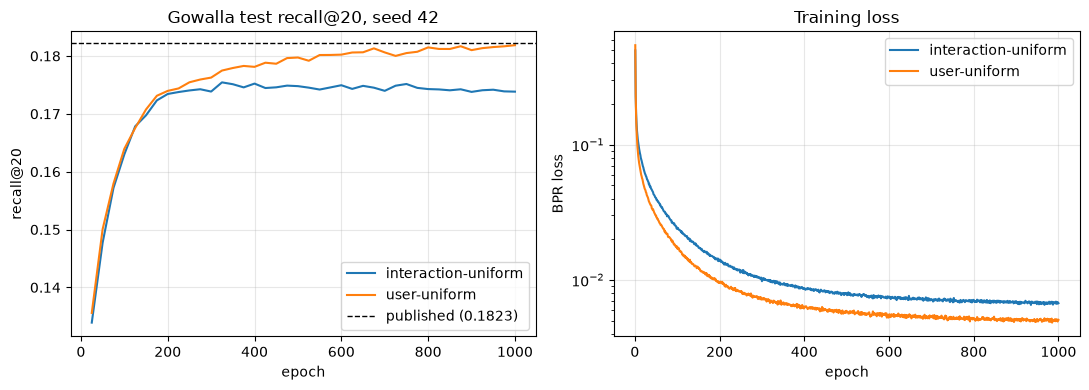

In [21]:
curves = {
    "interaction-uniform": gow_histories[("interaction", SEED)],
    "user-uniform": gow_histories[("user", SEED)],
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for label, h in curves.items():
    evaluated = h.dropna(subset=["val_recall@20"])
    axes[0].plot(evaluated["epoch"], evaluated["val_recall@20"], label=label)
    axes[1].plot(h["epoch"], h["loss"], label=label)

axes[0].axhline(0.1823, color="black", linestyle="--", linewidth=1,
                label="published (0.1823)")
axes[0].set(xlabel="epoch", ylabel="recall@20",
            title="Gowalla test recall@20, seed 42")
axes[1].set(xlabel="epoch", ylabel="BPR loss", yscale="log", title="Training loss")

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "09_gowalla_reproduction.png", dpi=200)
plt.show()

## 6. NGCF reproduction — follow-up verification after Notebook 10 results

This reproduction was added after the Notebook 10 results showed NGCF underperforming
matrix factorisation on Amazon. Since a negative result for a published method is only
as strong as the implementation behind it, NGCF needs the same external check as
LightGCN.

The published Gowalla results for 3-layer NGCF are Recall@20 = 0.1569 and
NDCG@20 = 0.1327 (Wang et al., 2019, as reported in He et al., 2020, Table 3).
The embedding size is 64 and the depth is 3, matching the published configuration.
Regularisation is searched because the comparison table does not report its value.

The run reuses the Gowalla split, graph, evaluator and training loop from the LightGCN
reproduction. This keeps the surrounding pipeline fixed, so the external check tests
the NGCF implementation rather than differences in data or evaluation.

In [22]:
NGCF_PAPER = {"recall@20": 0.1569, "ndcg@20": 0.1327}


def ngcf_gowalla_run(reg, epochs=400):
    """Same pattern as the LightGCN runs: train once, then read from disk."""
    path = GOWALLA_RESULTS / f"ngcf_reg{reg:g}.csv"
    if path.exists():
        return pd.read_csv(path)

    outcome = tr.train_bpr(
        md.NGCF(GOW_USERS, GOW_ITEMS, dim=64, seed=SEED,
                adjacency=gow_adj_fast, n_layers=3),
        gow_train, GOW_ITEMS, evaluator=gow_evaluator,
        epochs=epochs, batch_size=1024, learning_rate=1e-3, l2_reg=reg,
        sampling="user", patience=10 ** 6, eval_every=25,
        selection_metric="recall@20", device=DEVICE, seed=SEED, verbose=True,
    )
    outcome["history"].to_csv(path, index=False)
    return outcome["history"]


rows = []
for reg in [1e-4, 1e-3]:
    h = ngcf_gowalla_run(reg).dropna(subset=["val_recall@20"])
    best = h.loc[h["val_recall@20"].idxmax()]
    rows.append({"l2_reg": reg, "recall@20": best["val_recall@20"],
                 "ndcg@20": best["val_ndcg@20"], "best_epoch": int(best["epoch"])})

ngcf_gowalla = pd.DataFrame(rows)
ngcf_best = ngcf_gowalla.loc[ngcf_gowalla["recall@20"].idxmax()]
ngcf_gowalla.to_csv(RESULTS_DIR / "09_ngcf_reproduction.csv", index=False)

print(ngcf_gowalla.to_string(index=False, float_format="%.5f"))
for metric in ("recall@20", "ndcg@20"):
    gap = (ngcf_best[metric] - NGCF_PAPER[metric]) / NGCF_PAPER[metric]
    print(f"\nbest {metric:<10} {ngcf_best[metric]:.5f}   "
          f"paper {NGCF_PAPER[metric]:.4f}   {gap:+.1%}")

 l2_reg  recall@20  ndcg@20  best_epoch
0.00010    0.14437  0.11374         400
0.00100    0.15349  0.12224         400

best recall@20  0.15349   paper 0.1569   -2.2%

best ndcg@20    0.12224   paper 0.1327   -7.9%


## 7. Matrix factorisation on Gowalla

This section is not part of the verification. Instead, it provides a reference point
for the analysis in Notebook 12.

On the Amazon data, LightGCN outperforms matrix factorisation by 27% under
leave-last-out but is outperformed by a factor of 2.9 under the timestamp protocol.
One possible explanation is graph sparsity: users in Amazon Electronics have about
7 training interactions on average, compared with 27 in Gowalla. Training matrix
factorisation on Gowalla tests this hypothesis using the same models and training
pipeline on a much denser graph.

Matrix factorisation is tuned separately. On the Amazon data, its optimal
regularisation was roughly 500 times larger than LightGCN's, so reusing the graph
model's value would not provide a fair comparison.

One caveat is that Gowalla uses a released random split rather than a temporal split. This comparison should therefore be interpreted alongside the leave-last-out results, not the timestamp experiments.

In [23]:
def gowalla_mf_run(reg, seed=SEED, epochs=GOWALLA_EPOCHS, eval_every=25):
    """Matrix factorisation on Gowalla, cached like the other runs."""
    path = GOWALLA_RESULTS / f"mf_reg{reg:g}_s{seed}.csv"
    if path.exists():
        return pd.read_csv(path)

    outcome = tr.train_bpr(
        md.MatrixFactorization(GOW_USERS, GOW_ITEMS, LIGHTGCN_PAPER["dim"], seed),
        gow_train, GOW_ITEMS, evaluator=gow_evaluator,
        epochs=epochs, batch_size=LIGHTGCN_PAPER["batch_size"],
        learning_rate=LIGHTGCN_PAPER["learning_rate"], l2_reg=reg,
        sampling="user", eval_every=eval_every, selection_metric="recall@20",
        patience=10 ** 6, device=DEVICE, seed=seed, verbose=False,
    )
    outcome["history"].to_csv(path, index=False)
    return outcome["history"]


# Tune L2 regularisation for matrix factorisation on Gowalla
rows = []
for reg in [1e-4, 1e-3, 1e-2, 1e-1]:
    h = gowalla_mf_run(reg).dropna(subset=["val_recall@20"])
    best = h.loc[h["val_recall@20"].idxmax()]
    rows.append({"l2_reg": reg, "recall@20": best["val_recall@20"],
                 "ndcg@20": best["val_ndcg@20"], "best_epoch": int(best["epoch"])})
    print(rows[-1], flush=True)

gowalla_mf = pd.DataFrame(rows)
mf_best = gowalla_mf.loc[gowalla_mf["recall@20"].idxmax()]
gowalla_mf.to_csv(RESULTS_DIR / "09_gowalla_mf.csv", index=False)

gowalla_mf

{'l2_reg': 0.0001, 'recall@20': np.float64(0.146788015961647), 'ndcg@20': np.float64(0.1157375574111938), 'best_epoch': 925}
{'l2_reg': 0.001, 'recall@20': np.float64(0.1551483720541), 'ndcg@20': np.float64(0.1250031590461731), 'best_epoch': 925}
{'l2_reg': 0.01, 'recall@20': np.float64(0.1317500919103622), 'ndcg@20': np.float64(0.1050892174243927), 'best_epoch': 25}
{'l2_reg': 0.1, 'recall@20': np.float64(0.0937305241823196), 'ndcg@20': np.float64(0.07139203697443), 'best_epoch': 25}


,l2_reg,recall@20,ndcg@20,best_epoch
0,0.0001,0.146788,0.115738,925
1,0.0010,0.155148,0.125003,925
2,0.0100,0.131750,0.105089,25
3,0.1000,0.093731,0.071392,25


In [24]:
# Tune ItemKNN shrinkage on Gowalla

from src import baselines as bl

itemknn_path = RESULTS_DIR / "09_gowalla_itemknn.csv"

if itemknn_path.exists():
    gowalla_knn = pd.read_csv(itemknn_path)
else:
    rows = []
    for shrinkage in [0.0, 50.0, 200.0, 500.0, 1000.0]:
        knn = bl.ItemKNNRecommender(100, shrinkage=shrinkage).fit(
            gow_train, GOW_USERS, GOW_ITEMS, verbose=False)
        m = gow_evaluator.evaluate(knn.score_fn(DEVICE), return_per_user=False)["means"]
        rows.append({"shrinkage": shrinkage,
                     "recall@20": m["recall@20"], "ndcg@20": m["ndcg@20"]})
        print(rows[-1], flush=True)

    gowalla_knn = pd.DataFrame(rows)
    gowalla_knn.to_csv(itemknn_path, index=False)

knn_best = gowalla_knn.loc[gowalla_knn["recall@20"].idxmax()]
gowalla_knn

,shrinkage,recall@20,ndcg@20
0,0.0,0.115691,0.083935
1,50.0,0.143963,0.114519
2,200.0,0.142819,0.117706
3,500.0,0.139919,0.116654
4,1000.0,0.138591,0.115787


In [25]:
gowalla_summary = pd.DataFrame([
    {"model": "LightGCN", "recall@20": finals["recall@20"].mean(),
     "config": "3 layers, reg 5e-5"},
    {"model": "NGCF", "recall@20": ngcf_best["recall@20"],
     "config": f"3 layers, reg {ngcf_best['l2_reg']:g}"},
    {"model": "ItemKNN", "recall@20": knn_best["recall@20"],
     "config": f"100 neighbours, shrinkage {knn_best['shrinkage']:g}"},
    {"model": "BPR-MF", "recall@20": mf_best["recall@20"],
     "config": f"reg {mf_best['l2_reg']:g}"},
])
gowalla_summary["vs BPR-MF"] = gowalla_summary["recall@20"] / mf_best["recall@20"] - 1
gowalla_summary = gowalla_summary.sort_values("recall@20", ascending=False)
gowalla_summary.to_csv(RESULTS_DIR / "09_gowalla_density_reference.csv", index=False)

display_summary = gowalla_summary.copy()
display_summary["vs BPR-MF"] = display_summary["vs BPR-MF"].map(lambda x: f"{x:+.1%}")

print(display_summary.to_string(index=False))

   model  recall@20                       config vs BPR-MF
LightGCN   0.181843           3 layers, reg 5e-5    +17.2%
  BPR-MF   0.155148                    reg 0.001     +0.0%
    NGCF   0.153486          3 layers, reg 0.001     -1.1%
 ItemKNN   0.143963 100 neighbours, shrinkage 50     -7.2%


Matrix factorisation reaches Recall@20 0.15515 here against the 0.1291 reported for MF on
the same files (Wang et al., 2019, Table 2). The gain comes from two things documented
earlier in this notebook: user-uniform sampling, worth about 4.6% on Recall@20, and a regularisation
sweep with an interior optimum at 1e-3. NGCF's paper claims an 11.68% improvement over
its MF baseline; measured against this one, NGCF falls 1.1% below it.

In [2]:
# Table 4.1 - Gowalla reproduction against published values.
# Assembled from: results/09_gowalla_reproduction.csv, 09_ngcf_reproduction.csv,
#                 09_gowalla_mf.csv, 09_gowalla_itemknn.csv
# Read-only: nothing is retrained and no result file is written.
import pandas as pd, numpy as np

lg = pd.read_csv(RESULTS_DIR / "09_gowalla_reproduction.csv")
lg = lg[lg["sampling"] == "user"]                      # 3 seeds, adopted sampler
ngcf = pd.read_csv(RESULTS_DIR / "09_ngcf_reproduction.csv")
mf = pd.read_csv(RESULTS_DIR / "09_gowalla_mf.csv")
knn = pd.read_csv(RESULTS_DIR / "09_gowalla_itemknn.csv")

ngcf_sel = ngcf.loc[ngcf["recall@20"].idxmax()]        # l2_reg 1e-3
mf_sel = mf.loc[mf["recall@20"].idxmax()]              # l2_reg 1e-3
knn_sel = knn.loc[knn["recall@20"].idxmax()]           # shrinkage 50

table_4_1 = pd.DataFrame([
    {"model": "LightGCN", "seeds": len(lg),
     "recall@20": lg["recall@20"].mean(), "recall sd": lg["recall@20"].std(),
     "ndcg@20": lg["ndcg@20"].mean(),   "ndcg sd": lg["ndcg@20"].std(),
     "paper recall@20": 0.1823, "paper ndcg@20": 0.1555},
    {"model": "NGCF", "seeds": 1,
     "recall@20": ngcf_sel["recall@20"], "recall sd": np.nan,
     "ndcg@20": ngcf_sel["ndcg@20"], "ndcg sd": np.nan,
     "paper recall@20": 0.1569, "paper ndcg@20": 0.1327},
    {"model": "BPR-MF", "seeds": 1,
     "recall@20": mf_sel["recall@20"], "recall sd": np.nan,
     "ndcg@20": mf_sel["ndcg@20"], "ndcg sd": np.nan,
     "paper recall@20": 0.1291, "paper ndcg@20": np.nan},   # NDCG not reported
    {"model": "ItemKNN", "seeds": 1,
     "recall@20": knn_sel["recall@20"], "recall sd": np.nan,
     "ndcg@20": knn_sel["ndcg@20"], "ndcg sd": np.nan,
     "paper recall@20": np.nan, "paper ndcg@20": np.nan},
])
print("Table 4.1  Gowalla reproduction (final epoch, released random split)\n")
print(table_4_1.to_string(index=False, float_format=lambda v: f"{v:.5f}", na_rep="-"))
print(f"\nSelected: NGCF l2_reg {ngcf_sel['l2_reg']:g} (upper bound of grid), "
      f"BPR-MF l2_reg {mf_sel['l2_reg']:g}, ItemKNN shrinkage {knn_sel['shrinkage']:g}.")
print("Selection is on Recall@20; ItemKNN reaches a higher NDCG@20 "
      f"({knn['ndcg@20'].max():.5f}) at shrinkage "
      f"{knn.loc[knn['ndcg@20'].idxmax(), 'shrinkage']:g}.")

Table 4.1  Gowalla reproduction (final epoch, released random split)

   model  seeds  recall@20  recall sd  ndcg@20  ndcg sd  paper recall@20  paper ndcg@20
LightGCN      3    0.18184    0.00004  0.15542  0.00041          0.18230        0.15550
    NGCF      1    0.15349          -  0.12224        -          0.15690        0.13270
  BPR-MF      1    0.15515          -  0.12500        -          0.12910              -
 ItemKNN      1    0.14396          -  0.11452        -                -              -

Selected: NGCF l2_reg 0.001 (upper bound of grid), BPR-MF l2_reg 0.001, ItemKNN shrinkage 50.
Selection is on Recall@20; ItemKNN reaches a higher NDCG@20 (0.11771) at shrinkage 200.


## 8. Checks and saved results

The per-seed reproduction results are saved to `results/` so they can be reused in Notebook 10 without repeating the Gowalla training.

In [26]:
reproduction = finals.copy()
reproduction["sampling"] = "user"
reproduction["n_layers"] = LIGHTGCN_PAPER["layers"]
reproduction["dim"] = LIGHTGCN_PAPER["dim"]
reproduction["epochs"] = GOWALLA_EPOCHS
reproduction["paper_recall@20"] = 0.1823
reproduction["paper_ndcg@20"] = 0.1555

# the single-seed diagnostic run, kept because the sampler comparison is a finding
diagnostic = gow_histories[("interaction", SEED)] \
    .dropna(subset=["val_recall@20"]).iloc[-1]

reproduction = pd.concat([
    reproduction,
    pd.DataFrame([{
        "seed": SEED, "sampling": "interaction",
        "recall@20": diagnostic["val_recall@20"], "ndcg@20": diagnostic["val_ndcg@20"],
        "n_layers": LIGHTGCN_PAPER["layers"], "dim": LIGHTGCN_PAPER["dim"],
        "epochs": GOWALLA_EPOCHS,
        "paper_recall@20": 0.1823, "paper_ndcg@20": 0.1555,
    }]),
], ignore_index=True)

reproduction.to_csv(RESULTS_DIR / "09_gowalla_reproduction.csv", index=False)
print(reproduction.to_string(index=False, float_format="%.5f"))

 seed  recall@20  ndcg@20    sampling  n_layers  dim  epochs  paper_recall@20  paper_ndcg@20
    1    0.18180  0.15522        user         3   64    1000          0.18230        0.15550
    2    0.18187  0.15588        user         3   64    1000          0.18230        0.15550
   42    0.18186  0.15515        user         3   64    1000          0.18230        0.15550
   42    0.17383  0.14823 interaction         3   64    1000          0.18230        0.15550


In [27]:
mean_recall = finals["recall@20"].mean()
mean_ndcg = finals["ndcg@20"].mean()

checks = {
    "Gowalla matches the published statistics":
        (GOW_USERS, GOW_ITEMS, len(gow_all)) == (29_858, 40_981, 1_027_370),
    "adjacency is symmetric":
        gr.verify_symmetry(gow_edge_index),
    "spectral radius is 1":
        abs(radius - 1.0) < 1e-3,
    "0-layer LightGCN equals matrix factorisation":
        all(torch.equal(a, b) for a, b in zip(
            md.MatrixFactorization(n_users, n_items, VERIFY_DIM, SEED).to(DEVICE)(),
            md.LightGCN(n_users, n_items, dim=VERIFY_DIM, seed=SEED,
                        adjacency=adjacency, n_layers=0).to(DEVICE)())),
    "LightGCN recall@20 within 1% of published":
        abs(mean_recall - 0.1823) / 0.1823 < 0.01,
    "LightGCN ndcg@20 within 1% of published":
        abs(mean_ndcg - 0.1555) / 0.1555 < 0.01,
    "LightGCN seed variance is small":
        finals["recall@20"].std() < 1e-3,
    "user-uniform sampling outperforms interaction-uniform":
        mean_recall > diagnostic["val_recall@20"],
    "three LightGCN seeds recorded":
        len(finals) == 3,
    "NGCF recall@20 within 5% of published":
        abs(ngcf_best["recall@20"] - NGCF_PAPER["recall@20"])
        / NGCF_PAPER["recall@20"] < 0.05,
    "NGCF ndcg@20 within 10% of published":
        abs(ngcf_best["ndcg@20"] - NGCF_PAPER["ndcg@20"])
        / NGCF_PAPER["ndcg@20"] < 0.10,
}

width = max(len(k) for k in checks)
for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}  {name:<{width}}")

assert all(checks.values()), [k for k, v in checks.items() if not v]
print(f"\nall {len(checks)} checks passed")

PASS  Gowalla matches the published statistics             
PASS  adjacency is symmetric                               
PASS  spectral radius is 1                                 
PASS  0-layer LightGCN equals matrix factorisation         
PASS  LightGCN recall@20 within 1% of published            
PASS  LightGCN ndcg@20 within 1% of published              
PASS  LightGCN seed variance is small                      
PASS  user-uniform sampling outperforms interaction-uniform
PASS  three LightGCN seeds recorded                        
PASS  NGCF recall@20 within 5% of published                
PASS  NGCF ndcg@20 within 10% of published                 

all 11 checks passed


## Findings

The implementations are correct in a strong sense. LightGCN with zero layers is exactly
matrix factorisation, propagation matches the definition when recomputed by hand, and
three seeds on Gowalla give Recall@20 0.18184 +/- 0.00004 against a published 0.1823,
with NDCG@20 reproducing within seed variance. The residual 0.25% on Recall is larger
than seed noise but partly an estimator difference: the paper reports the best of roughly
100 test evaluations while these runs report the final epoch, worth about 0.00024 on
seed 1.

The most consequential finding concerns sampling. LightGCN's released code draws a user
uniformly and then one of that user's items, rather than sampling interactions directly.
This is not described in the paper, and it is worth 4.6% of Recall@20 here (0.17383 to
0.18186), more than the 3.9% the paper itself reports for increasing propagation depth
from one layer to three. All later notebooks therefore use user-uniform sampling for every model.

NGCF reproduces to within 2.2% on Recall@20 using the same graph, evaluator and training
loop, so the later result that NGCF underperforms matrix factorisation on Amazon
Electronics reflects the data regime rather than the implementation. NDCG@20 reproduces
less closely, 7.9% below, most plausibly because this implementation applies a single
message dropout where NGCF uses both message and node dropout. Both figures are lower
bounds: the selected regularisation sat at the top of the searched range, and the best
evaluation fell on the final epoch of the budget, although the score fluctuated within a
narrow band from epoch 200 rather than continuing to rise.

GraphSAGE has no comparable published benchmark on these datasets, so it is verified
structurally but not reproduced, and is treated as an adaptation throughout.